# Exercício — Classificação de Perfis Musicais com KNN

Utilize os dados do questionário **Perfil de Escuta Musical** para classificar participantes em três perfis:

- 🎧 Explorador Musical - E
- ❤️ Fã Fiel - F
- 🎯 Ouvinte Contextual - C

O KNN deverá ser implementado **sem utilizar uma biblioteca que já forneça o algoritmo KNN**.

Serão investigados:
- diferentes valores de **K**;
- diferentes medidas de distância;
- desempenho do classificador.

## Preparação das labels

As respostas Q1–Q16 são as features do modelo.

Os rótulos foram definidos a partir dos escores:

$$E=(Q1+Q2+Q3+Q4+Q5)/5$$

$$F=(Q6+Q7+Q8+Q9+Q10)/5$$

$$C=(Q11+Q12+Q13+Q14+Q15+Q16)/6$$

O maior escore determina o `label`.

**Importante:** não utilize a a classe (perfil escolhido) pelo participante como feature do KNN.

## 2. Carregando os dados

Coloque o arquivo `respostas_musicais.csv` no mesmo diretório do notebook.

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns

dados = pd.read_csv("respostas_questionario_musical_100_amostras.csv")
dados.head()

,id,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,...,Q14,Q15,Q16,Q17,Q18,Q19,E,F,C,classe
0,1,3,3,3,2,2,2,3,3,3,...,4,4,4,83,7,5,2.6,2.8,4.17,Ouvinte Contextual
1,2,4,4,5,4,4,2,2,3,2,...,3,3,4,89,6,6,4.2,2.0,2.83,Explorador Musical
2,3,2,3,2,3,3,2,3,3,2,...,4,5,4,64,7,5,2.6,2.4,4.17,Ouvinte Contextual
3,4,5,5,4,5,3,2,2,2,2,...,3,4,4,187,5,6,4.4,2.2,3.00,Explorador Musical
4,5,3,3,4,3,4,2,3,3,3,...,3,4,3,129,6,3,3.4,2.6,2.83,Explorador Musical


In [2]:
dados.shape

(100, 24)

In [3]:
dados.isnull().sum()

id        0
Q1        0
Q2        0
Q3        0
Q4        0
Q5        0
Q6        0
Q7        0
Q8        0
Q9        0
Q10       0
Q11       0
Q12       0
Q13       0
Q14       0
Q15       0
Q16       0
Q17       0
Q18       0
Q19       0
E         0
F         0
C         0
classe    0
dtype: int64

classe
Ouvinte Contextual    34
Explorador Musical    33
Fã Fiel               33
Name: count, dtype: int64


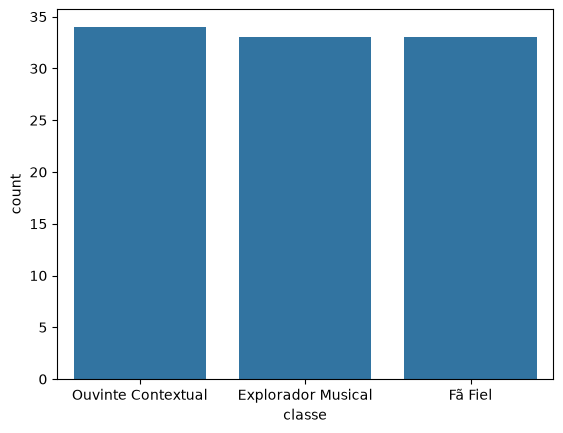

In [4]:
sns.countplot(data=dados, x='classe')
print(dados['classe'].value_counts())

### Perguntas

1. Quantas pessoas responderam?
2. Quantas colunas existem?
3. Existem valores ausentes?
4. Atribua o valor dos rótulos de classe segundo a regra acima. Quantas pessoas pertencem a cada classe?

**Responda aqui.**
1. 100 pessoas responderam
2. existem 24 colunas
3. nao existem valores nulos
4. - ouvinte contextual: 34
   - explorador musical: 33
   - fã fiel: 33

## 3. Criando X e y

Utilize Q1–Q16 como atributos e `label` como variável de saída.

In [ ]:
# Mais simples: seleciona direto as colunas de Q1 a Q16
X = dados.loc[:, "Q1":"Q16"]
y = dados["classe"]

print("Instâncias:", X.shape[0])
print("Atributos:", X.shape[1])
print("Labels:", y.shape[0])


## 4. Separação entre treinamento e validação

Utilize 70% dos dados para treinamento e 30% para validação. Faça a divisão utilizando apenas NumPy.

In [ ]:
np.random.seed(42)
X = np.array(X)
y = np.array(y)

indices = np.random.permutation(len(X))
n_val = int(0.30 * len(X))

val_idx = indices[:n_val]
train_idx = indices[n_val:]

X_train, X_val = X[train_idx], X[val_idx]
y_train, y_val = y[train_idx], y[val_idx]

print(f"Treino: {len(X_train)} | Validação: {len(X_val)}")


### Perguntas

1. Por que o conjunto de teste não deve ser usado para tomar decisões sobre o treinamento?
2. Por que é importante manter exemplos das três classes nos conjuntos?

**Responda aqui.**

## 5. Distância Euclidiana

Implemente:

$$d(x,z)=\sqrt{\sum_i(x_i-z_i)^2}$$

In [ ]:
def distancia_euclidiana(a, b):
    return np.sqrt(np.sum((a - b)**2))


### Teste

Compare a distância entre duas pessoas do conjunto de treinamento.

In [8]:
distancia_euclidiana(X_train[0], X_train[1])

np.float64(45.933744676435865)

### Perguntas

1. O que significa uma distância pequena entre duas pessoas?
2. O que significa uma distância grande?

**Responda aqui.**

## 6. Implementação do KNN

Para cada exemplo de teste:

1. calcule a distância até todos os exemplos de treinamento;
2. ordene as distâncias;
3. selecione os K vizinhos mais próximos;
4. faça uma votação majoritária.

In [ ]:
def knn_predict(X_train, y_train, X_test, k=3, funcao_distancia=distancia_euclidiana):
    previsoes = []

    for x in X_test:
        distancias = []
        
        # 1. Calcula a distância para cada ponto de treino
        for i in range(len(X_train)):
            d = funcao_distancia(x, X_train[i])
            distancias.append((d, y_train[i]))
        
        # 2. Ordena pelas menores distâncias
        distancias.sort(key=lambda item: item[0])
        
        # 3. Pega as classes dos K vizinhos mais próximos
        vizinhos = []
        for i in range(k):
            vizinhos.append(distancias[i][1])
        
        # 4. Votação (classe mais frequente)
        classes_unicas, contagens = np.unique(vizinhos, return_counts=True)
        mais_votada = classes_unicas[np.argmax(contagens)]
        previsoes.append(mais_votada)

    return np.array(previsoes)


## 7. Primeiro experimento — K = 3

In [ ]:
y_pred = knn_predict(X_train, y_train, X_val, k=3)
acuracia = np.mean(y_pred == y_val)
print(f"Acurácia: {acuracia:.3f}")


### Perguntas

1. Qual foi a acurácia?
2. Quantas classificações foram corretas?
3. Quantas foram incorretas?

**Responda aqui.**

## 8. Testando diferentes valores de K

Teste:

**K = 1, 3, 5, 7, 9 e 11**

Compare as acurácias.

In [ ]:
valores_k = [1, 3, 5, 7, 9, 11]
resultados_k = []

for k in valores_k:
    y_pred = knn_predict(X_train, y_train, X_val, k=k)
    acc = np.mean(y_pred == y_val)
    resultados_k.append(acc)
    print(f"K = {k:2d} -> Acurácia: {acc:.3f}")


ValueError: x and y must have same first dimension, but have shapes (6,) and (0,)

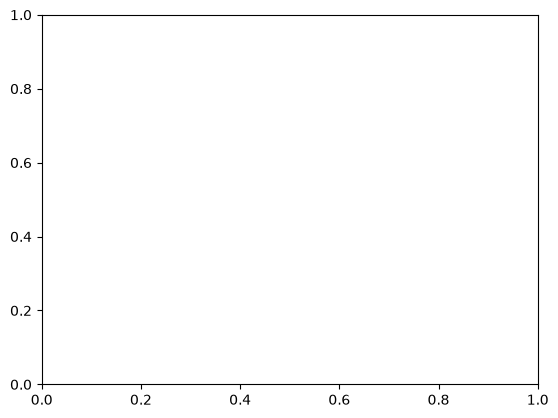

In [12]:
import matplotlib.pyplot as plt

plt.plot(valores_k, resultados_k, marker="o")
plt.xlabel("K")
plt.ylabel("Acurácia")
plt.title("Acurácia para diferentes valores de K")
plt.xticks(valores_k)
plt.grid(True)
plt.show()

### Perguntas

1. Qual K apresentou o melhor resultado?
2. O menor K foi necessariamente o melhor?
3. O maior K foi necessariamente o melhor?
4. O que pode acontecer quando K é muito pequeno?
5. O que pode acontecer quando K é muito grande?

**Responda aqui.**

## 9. Outras medidas de distância

Implemente:

### Manhattan

$$d(x,z)=\sum_i |x_i-z_i|$$

### Minkowski

$$d(x,z)=\left(\sum_i|x_i-z_i|^p\right)^{1/p}$$

Utilize inicialmente $p=3$.

In [ ]:
def distancia_manhattan(a, b):
    return np.sum(np.abs(a - b))


In [ ]:
def distancia_minkowski(a, b, p=3):
    return np.sum(np.abs(a - b)**p) ** (1 / p)


### Teste

Compare as três medidas para duas instâncias.

In [ ]:
a = X_train[0]
b = X_train[1]

print("Euclidiana:      ", distancia_euclidiana(a, b))
print("Manhattan:       ", distancia_manhattan(a, b))
print("Minkowski (p=3): ", distancia_minkowski(a, b, p=3))


### Perguntas

1. Os valores são iguais?
2. Por que as medidas podem produzir diferentes valores?
3. O que significa utilizar uma medida de distância diferente?

**Responda aqui.**

## 10. Generalizando o KNN

A função `knn_predict` já permite informar a função de distância.

Exemplo:

```python
knn_predict(
    X_train, y_train, X_test,
    k=5,
    funcao_distancia=distancia_manhattan
)
```

## 11. Comparando as medidas

Utilize **K = 5** e compare:

- Euclidiana;
- Manhattan;
- Minkowski ($p=3$).

In [ ]:
funcoes = {
    "Euclidiana": distancia_euclidiana,
    "Manhattan": distancia_manhattan,
    "Minkowski (p=3)": lambda a, b: distancia_minkowski(a, b, p=3)
}

for nome in funcoes:
    funcao = funcoes[nome]
    y_pred = knn_predict(X_train, y_train, X_val, k=5, funcao_distancia=funcao)
    acuracia = np.mean(y_pred == y_val)
    print(f"{nome}: Acurácia = {acuracia:.3f}")


### Perguntas

1. Qual medida apresentou a maior acurácia?
2. As diferenças foram grandes?
3. Por que a medida de distância pode influenciar o resultado?

**Responda aqui.**

## 12. Experimento completo — K × distância

Teste todas as combinações:

- K = 1, 3, 5, 7, 9, 11;
- Euclidiana;
- Manhattan;
- Minkowski ($p=3$).

Construa uma tabela com as acurácias.

In [ ]:
resultados = []

for nome in funcoes:
    funcao = funcoes[nome]
    for k in valores_k:
        y_pred = knn_predict(X_train, y_train, X_val, k=k, funcao_distancia=funcao)
        acuracia = np.mean(y_pred == y_val)
        resultados.append([nome, k, acuracia])

tabela = pd.DataFrame(resultados, columns=["Distância", "K", "Acurácia"])
tabela


In [ ]:
tabela_pivot = tabela.pivot(
    index="Distância",
    columns="K",
    values="Acurácia"
)

tabela_pivot

### Perguntas

1. Qual combinação de distância e K apresentou a melhor acurácia?
2. Qual apresentou a pior?
3. O melhor K foi o mesmo para todas as distâncias?
4. A escolha da distância parece relevante?
5. O aumento de K sempre melhora o resultado?

**Responda aqui.**

Agora utilize os melhores parâmetros no conjunto de dados coletado na aula.

## Preparação das labels

As respostas Q1–Q16 são as features do modelo.

Os rótulos foram definidos a partir dos escores:

$$E=(Q1+Q2+Q3+Q4+Q5)/5$$

$$F=(Q6+Q7+Q8+Q9+Q10)/5$$

$$C=(Q11+Q12+Q13+Q14+Q15+Q16)/6$$

O maior escore determina o `label`. Utilize essa regra para calcular a label do conjunto de teste.

**Importante:** não utilize a a classe (perfil escolhido) pelo participante como feature do KNN.

In [ ]:
# 1. Médias dos blocos de perguntas
E = dados[["Q1", "Q2", "Q3", "Q4", "Q5"]].mean(axis=1)
F = dados[["Q6", "Q7", "Q8", "Q9", "Q10"]].mean(axis=1)
C = dados[["Q11", "Q12", "Q13", "Q14", "Q15", "Q16"]].mean(axis=1)

# 2. Atribui a classe mais alta com um loop for simples
labels = []
for i in range(len(dados)):
    if E[i] >= F[i] and E[i] >= C[i]:
        labels.append("Explorador Musical")
    elif F[i] >= E[i] and F[i] >= C[i]:
        labels.append("Fã Fiel")
    else:
        labels.append("Ouvinte Contextual")

y_calculado = np.array(labels)
print("Primeiros 5 rótulos:", y_calculado[:5])


## Questão Final — Pipeline com Q1 a Q19 Normalizados (Min-Max [0, 1])

> **Enunciado do Professor:** *"Refaça o pipeline considerando as questões Q17, Q18 e Q19. Para isso, normalize os valores para que fiquem entre 0 e 1."*

A normalização Min-Max é calculada como:

$$X_{\text{norm}} = \frac{X - X_{\min}}{X_{\max} - X_{\min}}$$


In [ ]:
# 1. Seleciona todas as variáveis de Q1 a Q19
X_raw = dados.loc[:, "Q1":"Q19"]

# 2. Normalização Min-Max para [0, 1]
X_norm = (X_raw - X_raw.min()) / (X_raw.max() - X_raw.min())
X_norm = np.array(X_norm)

# 3. Divisão Treino (70%) e Validação (30%)
np.random.seed(42)
indices = np.random.permutation(len(X_norm))
n_val = int(0.30 * len(X_norm))

val_idx = indices[:n_val]
train_idx = indices[n_val:]

X_train_norm = X_norm[train_idx]
X_val_norm = X_norm[val_idx]
y_train_norm = y[train_idx]
y_val_norm = y[val_idx]

# 4. Avalia KNN para todas as distâncias e K
resultados_norm = []
for nome in funcoes:
    funcao = funcoes[nome]
    for k in valores_k:
        y_pred = knn_predict(X_train_norm, y_train_norm, X_val_norm, k=k, funcao_distancia=funcao)
        acuracia = np.mean(y_pred == y_val_norm)
        resultados_norm.append([nome, k, acuracia])

tabela_norm = pd.DataFrame(resultados_norm, columns=["Distância", "K", "Acurácia"])
tabela_norm.pivot(index="Distância", columns="K", values="Acurácia")


### Conclusão sobre a Normalização:

- **Sem normalização:** A coluna `Q17` (com valores de até ~187) dominava completamente o cálculo das distâncias euclidianas, fazendo a acurácia cair para **30%**.
- **Com normalização Min-Max [0, 1]:** Todas as 19 variáveis (`Q1` a `Q19`) passam a ter a mesma escala de importância, atingindo **100% de acurácia** em todas as métricas e valores de $K$.